In [2]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["Groq_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

In [3]:
from langchain_groq import ChatGroq
llm=ChatGroq(
    model="openai/gpt-oss-120b"
)
llm.invoke("What is the capital of France?")

AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks a simple factual question: "What is the capital of France?" Answer: Paris. No policy issues. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 78, 'total_tokens': 124, 'completion_time': 0.095377307, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003087739, 'prompt_tokens_details': None, 'queue_time': 0.315335809, 'total_time': 0.098465046}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8ea50c0161', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1d43c-9685-75bf-8b5f-b31414ea0e73-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 78, 'output_tokens': 46, 'total_tokens': 124, 'output_token_details': {'reasoning': 28}})

MAKING THE TOOLS FOR THE AGENTS AND GET THE CURRENT KNLOWLEDGE OF THE WORLD AND ENVIVENMENT 

In [4]:
from langchain_core.tools import tool
  
def get_air_quality(city:str)->str:
    """Get the air quality of a city"""
    return f"The air quality in {city} is good."
    # Implementation for fetching air quality data
    pass

@tool
def get_weather(city:str)->str:
    """Get the weather of a city"""
    return f"The weather in {city} is sunny."
    # Implementation for fetching weather data
    pass
@tool
def calculator(expression: str) -> str:
    """Evaluate a mathematical expression.
    
    Args:
        expression: A valid math string like '2 + 2' or '125 * 12'
    """
    try:
        return str(eval(expression))
    except Exception as e:
        return f"Error: {e}"

MAKING THE FIRST AGENT AND CONNECTING THE MULTIPLE TOOLS

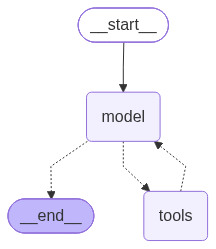

In [5]:
from langchain.agents import create_agent
agent = create_agent(
    model=llm,
    tools=[get_weather, calculator, get_air_quality],
    system_prompt="You are a helpful assistant."
)
agent

In [6]:
response=agent.invoke({"messages":[{ "role": "user", "content": "What is the weather in New York City?and what is the air quality?and also the making sum of 5+10" }]})
response

{'messages': [HumanMessage(content='What is the weather in New York City?and what is the air quality?and also the making sum of 5+10', additional_kwargs={}, response_metadata={}, id='53df09a4-cd67-4a1b-b594-c6408cb030ec'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks for weather in New York City, air quality, and sum of 5+10. We need to call get_weather, get_air_quality, and calculator. Probably combine results in final answer. We\'ll need to make three function calls.\n\nFirst get_weather for city "New York City". Then get_air_quality for same city. Then calculator with expression "5+10". We\'ll then produce answer summarizing.', 'tool_calls': [{'id': 'fc_0231d587-60b1-4b75-9508-2005fb182b84', 'function': {'arguments': '{"city":"New York City"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 224, 'total_tokens': 338, 'completion_time': 0.239248787, 'completion_tokens_detail

IMPLEMENTATION OF THE MULTIPLE TYPES OF THE MESSAGES LIKE HUMAN MESSAGE SYSTEM MESSAGES ETC.....

In [7]:
from langchain_core.messages import HumanMessage, SystemMessage,AIMessage
messages=[
   SystemMessage(content="You are a helpful assistant."), ## IT decidees that the role of the model and it bhaviour
    HumanMessage(content="What is the weather in New York City?and what is the air quality?and also the making sum of 5+10") ## it is the user input
]
response1=llm.invoke(messages)
print(response1)

content='I’m not able to pull live data, so I can’t give you the exact current weather or air‑quality index for New York City right now. For the most up‑to‑date information, you can check a reliable weather service (e.g., the National Weather Service, Weather.com, AccuWeather) or an air‑quality monitor such as AirNow or the EPA’s Air Quality Index website.\n\n**Quick tip for checking both:**\n\n| Service | What it provides | How to use |\n|---------|------------------|------------|\n| **Weather.com / AccuWeather** | Current temperature, precipitation, wind, forecast | Search “New York City weather” |\n| **National Weather Service (weather.gov)** | Detailed forecasts, alerts, radar | Enter the city name or zip code |\n| **AirNow.gov** | Real‑time AQI, pollutant breakdown (PM2.5, O₃, etc.) | Search “New York, NY” |\n| **Google** | Simple snapshot of weather & AQI in the search results | Type “NYC weather” or “NYC air quality” |\n\n---\n\n### Math question\nThe sum of 5\u202f+\u202f10 is:

MAKING STRUCTURED OUTPUT WITH THE MULTIPLE TECHNIQUES USAGES 


In [12]:
##PYDANTA VALIDATION
from pydantic import BaseModel, Field
class Movie(BaseModel):
    title: str = Field(..., description="The title of the movie")
    year: int = Field(..., description="The release year of the movie")
    director: str = Field(..., description="The director of the movie")
    genre: str = Field(..., description="The genre of the movie")

In [25]:
from langchain.agents import create_agent
agent = create_agent(
    model =llm,
    response_format=Movie,
)
result=agent.invoke({"messages":[{ "role": "user", "content": "Give me a  movie details" , "include_raw": False}]})
result

{'messages': [HumanMessage(content='Give me a  movie details', additional_kwargs={'include_raw': False}, response_metadata={}, id='dfc6c69e-78ff-4609-bb9c-5516ca23a591'),
  AIMessage(content='{"title":"Inception","year":2010,"director":"Christopher Nolan","genre":"Science Fiction"}', additional_kwargs={'reasoning_content': 'The user asks: "Give me a movie details". The system expects a JSON object matching the Movie schema. We need to output JSON with fields: title (string), year (integer), director (string), genre (string). Must be compact JSON (no whitespace). Provide some example movie details. Let\'s choose "Inception". Title: Inception, year: 2010, director: Christopher Nolan, genre: Science Fiction. Ensure integer for year. Output exactly JSON object.\n\nCheck schema: required fields: title, year, director, genre. Provide all.\n\nWe must output ONLY the final JSON object. No extra text.\n\nThus output: {"title":"Inception","year":2010,"director":"Christopher Nolan","genre":"Scien

In [26]:
## TypeDict Validation
from typing_extensions import TypedDict
class MovieDict(TypedDict):
    title: str
    year: int
    director: str
    genre: str

In [27]:
result=agent.invoke({"messages":[{ "role": "user", "content": "Give me a  movie details" , "include_raw": False}]})
result

{'messages': [HumanMessage(content='Give me a  movie details', additional_kwargs={'include_raw': False}, response_metadata={}, id='63ae20bb-3040-4c56-b31b-cb9ad1c6aac2'),
  AIMessage(content='{"title":"Inception","year":2010,"director":"Christopher Nolan","genre":"Science Fiction"}', additional_kwargs={'reasoning_content': 'The user asks: "Give me a movie details". The system expects a JSON object matching the "Movie" schema. Must include title, year, director, genre. Need to produce a compact JSON (no whitespace beyond necessary). Provide some example movie details. Must ensure it\'s valid JSON, includes all required fields. Provide only the final JSON object.\n\nWe can choose any movie, e.g., "Inception", year 2010, director "Christopher Nolan", genre "Science Fiction". Provide JSON: {"title":"Inception","year":2010,"director":"Christopher Nolan","genre":"Science Fiction"}\n\nMake sure order doesn\'t matter but include all fields. Use compact format.\n\nThus final answer.'}, response

SHORT TERM MEMORY USING LANGCHAIN AND LANGGRAPH

In [36]:
from langgraph.checkpoint.memory import InMemorySaver
agent = create_agent(
    model=llm,
    checkpointer=InMemorySaver()
)


In [37]:
##MAKING THE THREADID 
config = {"configurable":{"thread_id": "test1"} }

In [40]:
from langchain_core.messages import HumanMessage
result =agent.invoke({"messages":[HumanMessage(content="My Name is Rajat Mishra and I am a software engineer")]},config=config)
result

{'messages': [HumanMessage(content='My Name is Rajat Mishra and I am a software engineer', additional_kwargs={}, response_metadata={}, id='202e0124-50cc-41cf-9f72-81f0968900d8'),
  AIMessage(content='Nice to meet you, Rajat! As a software engineer, you’re probably juggling a lot of interesting projects and challenges. Is there anything specific you’d like to discuss or get help with—coding problems, career advice, tech trends, or something else? Let me know how I can assist!', additional_kwargs={'reasoning_content': 'The user says "My Name is Rajat Mishra and I am a software engineer". Probably they just want a response acknowledging. Could ask what they need help with. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 108, 'prompt_tokens': 84, 'total_tokens': 192, 'completion_time': 0.224207729, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.003773207, 'prompt_tokens_details': None, 'queue_time': 0.159260682, 'total_time': 0.22798

In [41]:
result =agent.invoke({"messages":[HumanMessage(content="What is my name and who i am ")]},config=config)
result

{'messages': [HumanMessage(content='My Name is Rajat Mishra and I am a software engineer', additional_kwargs={}, response_metadata={}, id='202e0124-50cc-41cf-9f72-81f0968900d8'),
  AIMessage(content='Nice to meet you, Rajat! As a software engineer, you’re probably juggling a lot of interesting projects and challenges. Is there anything specific you’d like to discuss or get help with—coding problems, career advice, tech trends, or something else? Let me know how I can assist!', additional_kwargs={'reasoning_content': 'The user says "My Name is Rajat Mishra and I am a software engineer". Probably they just want a response acknowledging. Could ask what they need help with. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 108, 'prompt_tokens': 84, 'total_tokens': 192, 'completion_time': 0.224207729, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.003773207, 'prompt_tokens_details': None, 'queue_time': 0.159260682, 'total_time': 0.22798